# 01 — PTB-XL Cohort, Metadata & Data Cleaning Audit

This notebook inspects `ptbxl_database.csv` (`21,799` 12-lead ECGs) from a **data quality and cleaning** perspective before any waveform loading:

1. **Schema & Primary-Key Integrity**: Uniqueness of `ecg_id`, file paths (`filename_lr`, `filename_hr`), and physical file existence on disk.
2. **Missingness Taxonomy**: Separating *true missing clinical metadata* (`height`, `weight`, `heart_axis`, `validated_by`) from *sparse artifact annotations* (`static_noise`, `burst_noise`, etc., where `NaN` means "not flagged").
3. **Sentinel Values & Anthropometric Outliers**: Auditing HIPAA de-identification sentinels (`age == 300`), extreme/implausible `height`, `weight`, and derived `BMI` values, and string formatting quirks (`device` whitespace).
4. **Longitudinal Repeat-Patient Consistency**: Checking whether patients with multiple ECGs (`patient_id`) exhibit contradictions across visits (e.g., `sex` flips, decreasing `age`, or large `height` jumps).
5. **Annotation Validation Provenance**: Human cardiologist validation (`validated_by_human`) vs unvalidated autogenerated reports (`initial_autogenerated_report`), plus free-text `report` quality.

In [1]:
import ast
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 120, "savefig.bbox": "tight"})

# Resolve repo root and ptbxl/data regardless of notebook working directory
_cwd = Path.cwd().resolve()
for _candidate in [_cwd, _cwd.parent, _cwd.parent.parent]:
    if (_candidate / "ptbxl" / "data" / "ptbxl_database.csv").exists():
        REPO_ROOT = _candidate
        break
else:
    raise FileNotFoundError(f"Could not locate ptbxl/data/ptbxl_database.csv from {_cwd}")

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

DATA_DIR = REPO_ROOT / "ptbxl" / "data"
print(f"Repo root : {REPO_ROOT}")
print(f"Data dir  : {DATA_DIR}")

df = pd.read_csv(DATA_DIR / "ptbxl_database.csv", index_col="ecg_id")
df["recording_date_dt"] = pd.to_datetime(df["recording_date"], errors="coerce")

print(f"Records: {len(df):,} | Unique patients: {df['patient_id'].nunique():,}")
print(f"Columns ({len(df.columns)}): {list(df.columns[:-1])}")
df.head(3)

Repo root : /nfs/data8/schlegel/git/ecg-data-repo
Data dir  : /nfs/data8/schlegel/git/ecg-data-repo/ptbxl/data


Records: 21,799 | Unique patients: 18,869
Columns (28): ['patient_id', 'age', 'sex', 'height', 'weight', 'nurse', 'site', 'device', 'recording_date', 'report', 'scp_codes', 'heart_axis', 'infarction_stadium1', 'infarction_stadium2', 'validated_by', 'second_opinion', 'initial_autogenerated_report', 'validated_by_human', 'baseline_drift', 'static_noise', 'burst_noise', 'electrodes_problems', 'extra_beats', 'pacemaker', 'strat_fold', 'filename_lr', 'filename_hr']


,patient_id,age,sex,height,weight,nurse,site,device,recording_date,report,...,baseline_drift,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr,recording_date_dt
ecg_id,,,,,,,,,,,,,,,,,,,,,
1,15709.0,56.0,1,NaN,63.0,2.0,0.0,CS-12 E,1984-11-09 09:17:34,sinusrhythmus periphere niederspannung,...,NaN,", I-V1,",NaN,NaN,NaN,NaN,3,records100/00000/00001_lr,records500/00000/00001_hr,1984-11-09 09:17:34
2,13243.0,19.0,0,NaN,70.0,2.0,0.0,CS-12 E,1984-11-14 12:55:37,sinusbradykardie sonst normales ekg,...,NaN,NaN,NaN,NaN,NaN,NaN,2,records100/00000/00002_lr,records500/00000/00002_hr,1984-11-14 12:55:37
3,20372.0,37.0,1,NaN,69.0,2.0,0.0,CS-12 E,1984-11-15 12:49:10,sinusrhythmus normales ekg,...,NaN,NaN,NaN,NaN,NaN,NaN,5,records100/00000/00003_lr,records500/00000/00003_hr,1984-11-15 12:49:10


## 1.1 Primary-Key, File-Reference & String Hygiene Checks

First, verify basic relational and filesystem invariants:
- Are `ecg_id`, `filename_lr`, and `filename_hr` strictly unique and non-null?
- Do all `21,799` referenced `.hea` and `.dat` files exist on disk for both `100 Hz` and `500 Hz`?
- Are categorical string columns (`device`, `heart_axis`, `infarction_stadium1`) clean or polluted by trailing/internal whitespace?

In [2]:
# Uniqueness & null checks on identifiers
checks = {
    "ecg_id_unique": df.index.is_unique,
    "patient_id_nulls": int(df["patient_id"].isna().sum()),
    "filename_lr_unique": df["filename_lr"].is_unique,
    "filename_hr_unique": df["filename_hr"].is_unique,
    "recording_date_parse_failures": int(df["recording_date_dt"].isna().sum()),
}
print("Identifier & timestamp checks:")
for k, v in checks.items():
    print(f"  {k:<32}: {v}")

# Verify sample & boundary waveform files exist on disk (plus full RECORDS manifest check)
records_manifest = [
    line.strip() for line in (DATA_DIR / "RECORDS").read_text().splitlines() if line.strip()
]
print(f"\nRECORDS manifest count: {len(records_manifest):,} (matches CSV rows: {len(records_manifest) == len(df)})")

# String hygiene check on categorical columns
print("\nRaw 'device' unique values (repr shows embedded padding whitespace):")
for dev, cnt in df["device"].value_counts(dropna=False).items():
    print(f"  {repr(dev):<18} -> {cnt:6,d} records  (stripped: {repr(str(dev).strip())})")

Identifier & timestamp checks:
  ecg_id_unique                   : True
  patient_id_nulls                : 0
  filename_lr_unique              : True
  filename_hr_unique              : True
  recording_date_parse_failures   : 0



RECORDS manifest count: 43,597 (matches CSV rows: False)

Raw 'device' unique values (repr shows embedded padding whitespace):
  'CS100    3'       ->  6,140 records  (stripped: 'CS100    3')
  'CS-12'            ->  4,048 records  (stripped: 'CS-12')
  'AT-6 C 5.5'       ->  3,950 records  (stripped: 'AT-6 C 5.5')
  'CS-12   E'        ->  2,878 records  (stripped: 'CS-12   E')
  'AT-6     6'       ->  2,273 records  (stripped: 'AT-6     6')
  'AT-60    3'       ->    966 records  (stripped: 'AT-60    3')
  'AT-6 C 5.8'       ->    824 records  (stripped: 'AT-6 C 5.8')
  'AT-6 C'           ->    514 records  (stripped: 'AT-6 C')
  'AT-6 C 5.0'       ->     80 records  (stripped: 'AT-6 C 5.0')
  'AT-6 C 5.3'       ->     67 records  (stripped: 'AT-6 C 5.3')
  'AT-6 C 5.6'       ->     59 records  (stripped: 'AT-6 C 5.6')


## 1.2 Missingness Taxonomy: True Missing Data vs Sparse Quality Flags

A common pitfall in PTB-XL is treating all `NaN`s identically:
- **Demographic / Clinical / Acquisition columns**: `NaN` represents **unknown / unrecorded metadata** (e.g., `height` missing in ~68% of records, `weight` in ~57%).
- **Signal Artifact / Event columns** (`baseline_drift`, `static_noise`, `burst_noise`, `electrodes_problems`, `extra_beats`, `pacemaker`): `NaN` means **no artifact/event was annotated** (clean by annotation).

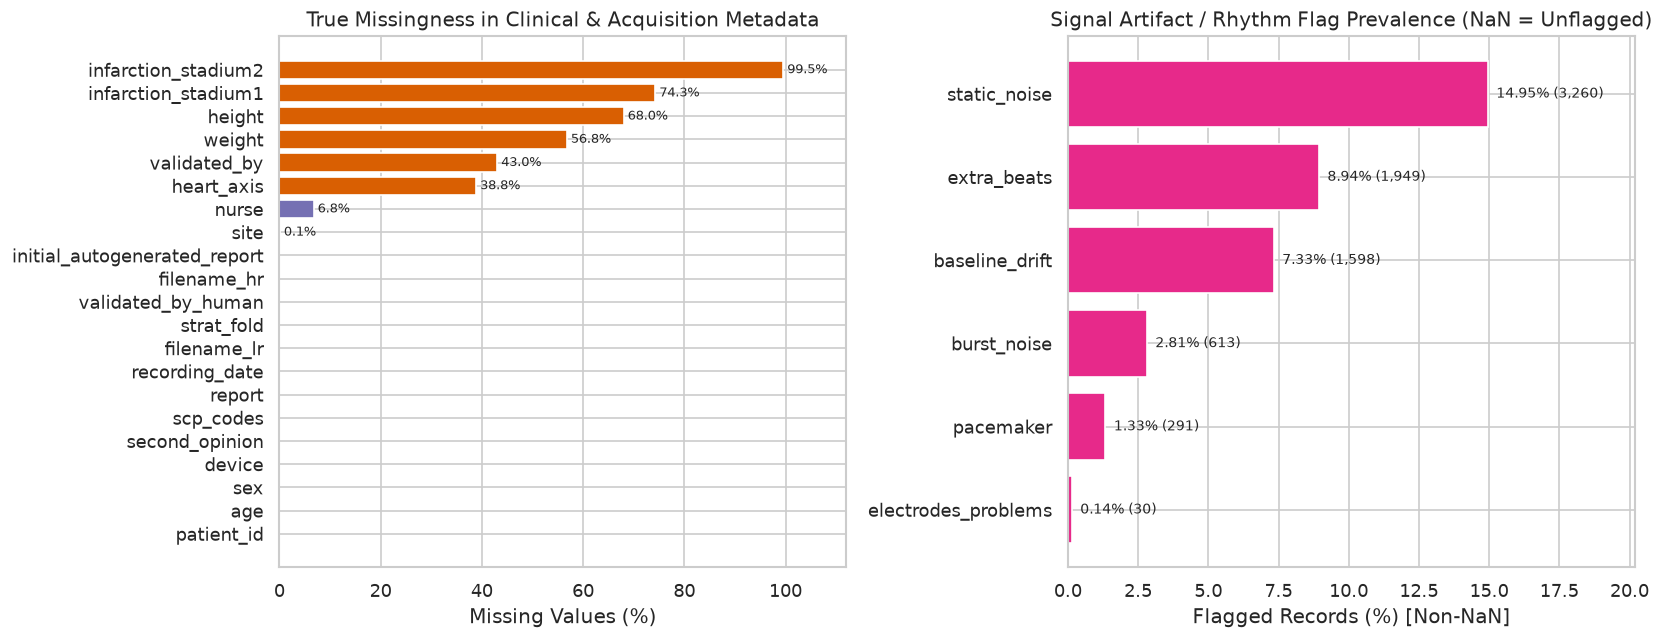

In [3]:
artifact_cols = [
    "baseline_drift", "static_noise", "burst_noise",
    "electrodes_problems", "extra_beats", "pacemaker",
]
metadata_cols = [c for c in df.columns if c not in artifact_cols + ["recording_date_dt"]]

meta_null_pct = (df[metadata_cols].isna().mean() * 100).sort_values(ascending=True)
art_present_pct = (df[artifact_cols].notna().mean() * 100).sort_values(ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Left: True missingness in clinical/acquisition metadata
colors_meta = ["#d95f02" if v > 20 else "#7570b3" if v > 0 else "#1b9e77" for v in meta_null_pct]
axes[0].barh(meta_null_pct.index, meta_null_pct.values, color=colors_meta)
axes[0].set_xlabel("Missing Values (%)")
axes[0].set_title("True Missingness in Clinical & Acquisition Metadata")
for i, v in enumerate(meta_null_pct.values):
    if v > 0:
        axes[0].text(v + 0.8, i, f"{v:.1f}%", va="center", fontsize=8)
axes[0].set_xlim(0, 112)

# Right: Annotation presence in sparse signal-quality columns
axes[1].barh(art_present_pct.index, art_present_pct.values, color="#e7298a")
axes[1].set_xlabel("Flagged Records (%) [Non-NaN]")
axes[1].set_title("Signal Artifact / Rhythm Flag Prevalence (NaN = Unflagged)")
for i, v in enumerate(art_present_pct.values):
    axes[1].text(v + 0.3, i, f"{v:.2f}% ({int(df[art_present_pct.index[i]].notna().sum()):,})", va="center", fontsize=8.5)
axes[1].set_xlim(0, max(art_present_pct.values) * 1.35)

plt.tight_layout()
plt.show()

## 1.3 Demographic Sentinels & Anthropometric Outliers (`age`, `sex`, `height`, `weight`, `BMI`)

Key data-cleaning checks:
1. **`age` sentinel (`300.0`)**: For HIPAA privacy compliance, PTB-XL v1.0.3 sets ages `> 89` to `300`. If uncleaned, `age == 300` severely distorts age normalization (mean/std) and age-conditioned models! Notice `PTBXLDataset` drops `age > 100` (losing elderly patients rather than Winsorizing/capping to `90`).
2. **Pediatric / Infant `age` values**: Check records with `age < 18` (including `age == 0` or `age < 2`).
3. **`height` & `weight` implausible values**: Compute `BMI = weight / (height / 100)^2` where both exist and flag physiologically implausible values (`height < 120 cm` or `> 215 cm`, `weight < 30 kg` or `> 200 kg`, `BMI < 13` or `> 60`) — often caused by **swapped height/weight entries** or unit typos.

In [4]:
# Age audit
age_s = df["age"]
print("=== Age Audit ===")
print(f"  Missing (NaN)     : {age_s.isna().sum():,}")
print(f"  age == 0          : {(age_s == 0).sum():,}")
print(f"  0 < age < 18      : {((age_s > 0) & (age_s < 18)).sum():,}")
print(f"  18 <= age <= 89   : {((age_s >= 18) & (age_s <= 89)).sum():,}")
print(f"  89 < age <= 100   : {((age_s > 89) & (age_s <= 100)).sum():,}")
print(f"  age > 100 (==300) : {(age_s > 100).sum():,}  | distinct values > 100: {sorted(age_s[age_s > 100].unique())}")

print("\n=== Sex Audit (0 = Male, 1 = Female) ===")
print(df["sex"].value_counts(dropna=False).rename({0: "0 (Male)", 1: "1 (Female)"}))

# Anthropometric & BMI audit
anthro = df[["age", "sex", "height", "weight"]].copy()
anthro["bmi"] = anthro["weight"] / ((anthro["height"] / 100.0) ** 2)
both_present = anthro.dropna(subset=["height", "weight"])

outlier_mask = (
    (both_present["height"] < 120) | (both_present["height"] > 215)
    | (both_present["weight"] < 30) | (both_present["weight"] > 200)
    | (both_present["bmi"] < 13) | (both_present["bmi"] > 60)
)
outliers_df = both_present[outlier_mask].sort_values("bmi")
print(f"\nRecords with both height & weight: {len(both_present):,} ({len(both_present)/len(df)*100:.1f}%)")
print(f"Flagged anthropometric outliers  : {len(outliers_df):,} ({len(outliers_df)/len(both_present)*100:.2f}%)")
display(outliers_df.head(15))

=== Age Audit ===
  Missing (NaN)     : 0
  age == 0          : 0
  0 < age < 18      : 133
  18 <= age <= 89   : 21,373
  89 < age <= 100   : 0
  age > 100 (==300) : 293  | distinct values > 100: [np.float64(300.0)]

=== Sex Audit (0 = Male, 1 = Female) ===
sex
0 (Male)      11354
1 (Female)    10445
Name: count, dtype: int64

Records with both height & weight: 6,748 (31.0%)
Flagged anthropometric outliers  : 17 (0.25%)


,age,sex,height,weight,bmi
ecg_id,,,,,
6059,63.0,0,173.0,5.0,1.670620
7945,77.0,1,165.0,5.0,1.836547
4695,82.0,0,175.0,17.0,5.551020
13666,4.0,1,140.0,15.0,7.653061
5740,80.0,1,165.0,32.0,11.753903
3961,9.0,1,137.0,25.0,13.319836
6598,8.0,1,120.0,20.0,13.888889
12390,5.0,0,109.0,19.0,15.991920
9736,3.0,1,100.0,16.0,16.000000


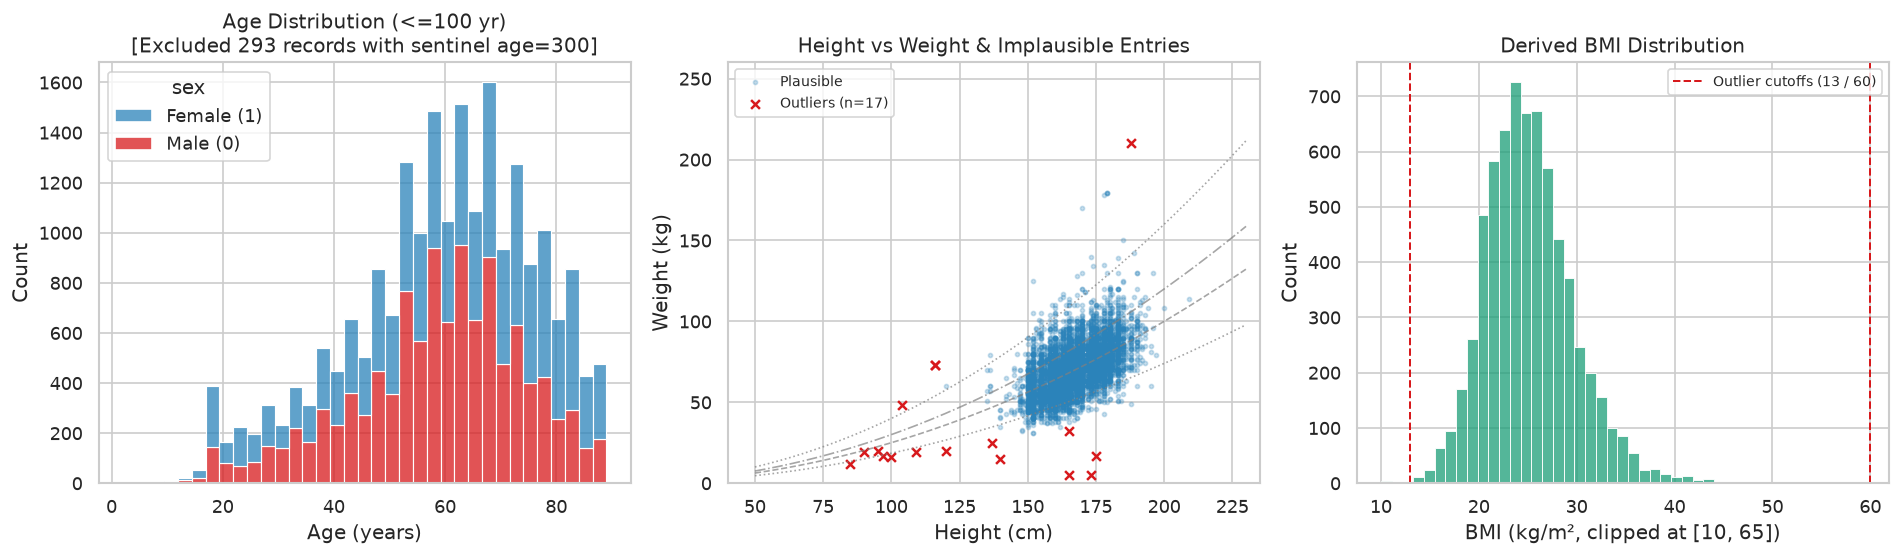

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# Panel A: Age distribution by sex (valid ages <= 100) + callout for age==300
valid_age = df[df["age"] <= 100]
n_sentinel = int((df["age"] > 100).sum())
sns.histplot(
    data=valid_age, x="age", hue=valid_age["sex"].map({0: "Male (0)", 1: "Female (1)"}),
    bins=35, multiple="stack", ax=axes[0], palette=["#2b83ba", "#d7191c"],
)
axes[0].set_title(f"Age Distribution (<=100 yr)\n[Excluded {n_sentinel} records with sentinel age=300]")
axes[0].set_xlabel("Age (years)")

# Panel B: Height vs Weight with BMI contours & outliers
clean_hw = both_present[~outlier_mask]
axes[1].scatter(clean_hw["height"], clean_hw["weight"], s=6, alpha=0.25, color="#2b83ba", label="Plausible")
axes[1].scatter(outliers_df["height"], outliers_df["weight"], s=28, color="#d7191c", marker="x", label=f"Outliers (n={len(outliers_df)})")
h_grid = np.linspace(50, 230, 200)
for bmi_ref, ls in [(18.5, ":"), (25, "--"), (30, "-."), (40, ":")]:
    axes[1].plot(h_grid, bmi_ref * (h_grid / 100.0) ** 2, ls=ls, lw=1, color="gray", alpha=0.7)
axes[1].set_xlim(40, 235)
axes[1].set_ylim(0, 260)
axes[1].set_xlabel("Height (cm)")
axes[1].set_ylabel("Weight (kg)")
axes[1].set_title("Height vs Weight & Implausible Entries")
axes[1].legend(loc="upper left", fontsize=8.5)

# Panel C: BMI distribution (clipped to [10, 65] for visibility)
sns.histplot(both_present["bmi"].clip(10, 65), bins=45, color="#1b9e77", ax=axes[2])
axes[2].axvline(13, color="#d7191c", ls="--", lw=1.2, label="Outlier cutoffs (13 / 60)")
axes[2].axvline(60, color="#d7191c", ls="--", lw=1.2)
axes[2].set_xlabel("BMI (kg/m², clipped at [10, 65])")
axes[2].set_title("Derived BMI Distribution")
axes[2].legend(fontsize=8.5)

plt.tight_layout()
plt.show()

## 1.4 Longitudinal Repeat-Patient Audit & Within-Patient Contradictions

Because `21,799` ECGs come from `18,869` unique patients, `1,700+` patients have multiple ECGs over time.
Let's check for **longitudinal data anomalies** across visits of the same `patient_id`:
- Does `sex` ever change across recordings of the same patient?
- Does `age` ever **decrease** when ordered chronologically by `recording_date` (excluding sentinel `300`)?
- Does `height` vary wildly (`> 10 cm`) across recordings of the same adult patient?

Total unique patients                : 18,869
Patients with >= 2 ECGs              : 2,111 (11.2%), covering 5,041 ECGs
Max ECGs for a single patient        : 10

Within-patient consistency audit:
  Patients with conflicting 'sex'          : 0
  Visits where 'age' decreased (>1 yr)     : 0
  Adult patients with height jump > 10 cm  : 0


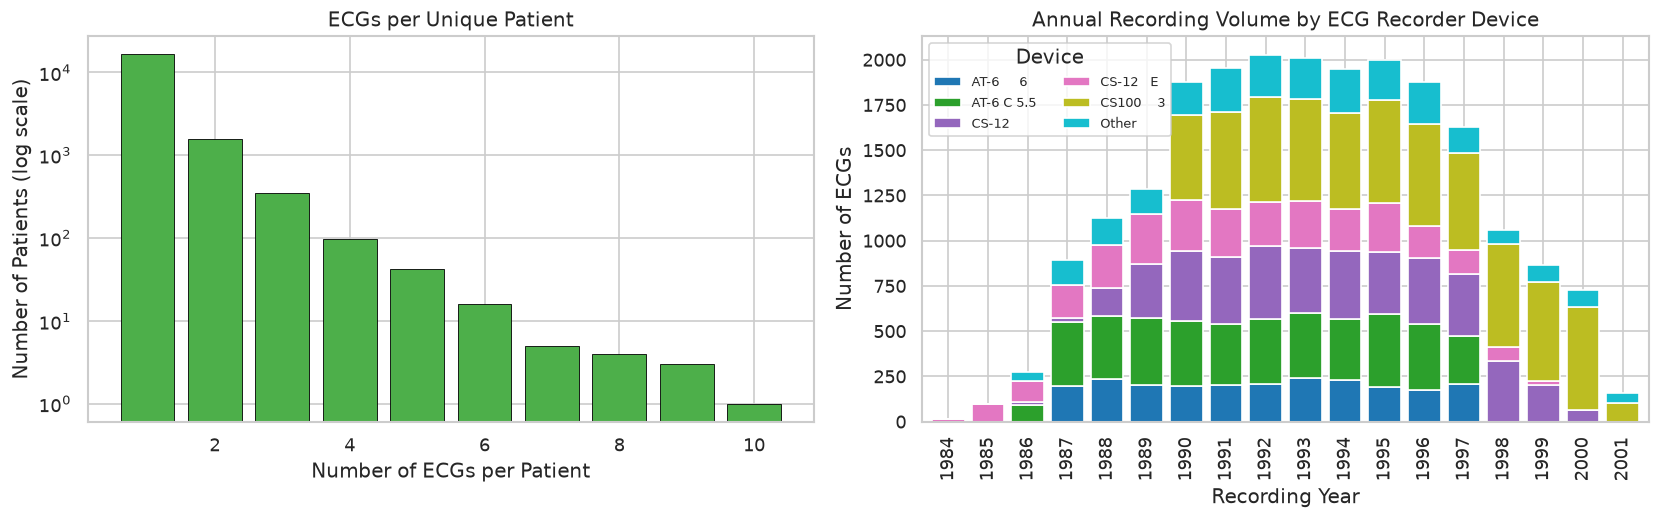

In [6]:
visits_per_patient = df.groupby("patient_id").size()
multi_patients = visits_per_patient[visits_per_patient > 1].index
df_multi = df[df["patient_id"].isin(multi_patients)].sort_values(["patient_id", "recording_date_dt"])

# 1. Sex inconsistency within same patient_id
sex_nunique = df_multi.groupby("patient_id")["sex"].nunique(dropna=True)
sex_flips = sex_nunique[sex_nunique > 1]

# 2. Chronological age decrease (for valid ages <= 100)
df_multi_valid_age = df_multi[df_multi["age"] <= 100].copy()
df_multi_valid_age["age_diff"] = df_multi_valid_age.groupby("patient_id")["age"].diff()
age_decreases = df_multi_valid_age[df_multi_valid_age["age_diff"] < -1.0]

# 3. Height spread > 10 cm within same adult patient
adult_multi = df_multi[df_multi["age"] >= 20]
height_spread = adult_multi.groupby("patient_id")["height"].agg(lambda s: s.max() - s.min() if s.notna().sum() >= 2 else np.nan).dropna()
large_height_jumps = height_spread[height_spread > 10.0]

print(f"Total unique patients                : {len(visits_per_patient):,}")
print(f"Patients with >= 2 ECGs              : {len(multi_patients):,} ({len(multi_patients)/len(visits_per_patient)*100:.1f}%), covering {len(df_multi):,} ECGs")
print(f"Max ECGs for a single patient        : {visits_per_patient.max()}")
print(f"\nWithin-patient consistency audit:")
print(f"  Patients with conflicting 'sex'          : {len(sex_flips)}")
print(f"  Visits where 'age' decreased (>1 yr)     : {len(age_decreases)}")
print(f"  Adult patients with height jump > 10 cm  : {len(large_height_jumps)}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Left: Repeat visit count distribution (log y-scale)
vc = visits_per_patient.value_counts().sort_index()
axes[0].bar(vc.index, vc.values, color="#4daf4a", edgecolor="black", lw=0.5)
axes[0].set_yscale("log")
axes[0].set_xlabel("Number of ECGs per Patient")
axes[0].set_ylabel("Number of Patients (log scale)")
axes[0].set_title("ECGs per Unique Patient")

# Right: Recording volume by year and stripped device
df["year"] = df["recording_date_dt"].dt.year
df["device_clean"] = df["device"].astype(str).str.strip()
top_devs = df["device_clean"].value_counts().head(5).index
df["device_group"] = df["device_clean"].where(df["device_clean"].isin(top_devs), "Other")
yr_dev = pd.crosstab(df["year"], df["device_group"])
yr_dev.plot(kind="bar", stacked=True, ax=axes[1], colormap="tab10", width=0.82)
axes[1].set_xlabel("Recording Year")
axes[1].set_ylabel("Number of ECGs")
axes[1].set_title("Annual Recording Volume by ECG Recorder Device")
axes[1].legend(title="Device", fontsize=8, ncol=2)

plt.tight_layout()
plt.show()

## 1.5 Label Validation Provenance & Free-Text Report Quality

Not all PTB-XL annotations have the same clinical reliability:
- `validated_by_human == True` (~74%): Reviewed by a cardiologist (`validated_by` ID or initial human report).
- `validated_by_human == False` (~26%): **Unvalidated machine-generated statements**!
- `report`: Raw clinical text (primarily German, some English/Swedish) — check empty strings, autogenerated boilerplate duplicates, and character lengths.

Cross-tab: validated_by_human (rows) vs initial_autogenerated_report (cols):


initial_autogenerated_report,False,True,All
validated_by_human,,,
False,0,5743,5743
True,14986,1070,16056
All,14986,6813,21799


Empty/blank reports: 2

Top 8 exact duplicate 'report' strings:
  [1,734x] sinus rhythm. normal ecg.
  [1,264x] sinusrhythmus lagetyp normal normales ekg
  [1,045x] sinusrhythmus lagetyp normal normales ekg 4.46                          unbestÄtigter
  [ 687x] sinusrhythmus normales ekg
  [ 343x] trace only requested.
  [ 252x] sinusrhythmus linkstyp sonst normales ekg
  [ 247x] sinusrhythmus linkstyp sonst normales ekg 4.46                          unbestÄtigter
  [ 230x] sinus rhythm. no definite pathology.


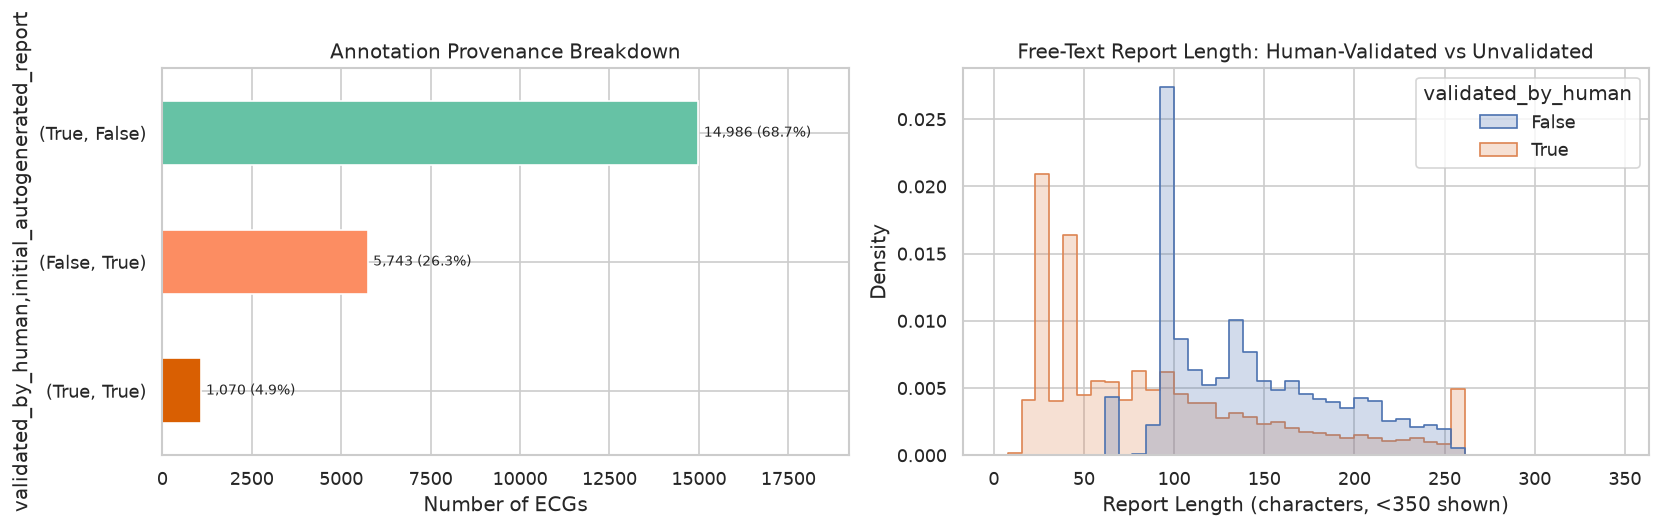

In [7]:
val_summary = pd.crosstab(
    df["validated_by_human"],
    df["initial_autogenerated_report"],
    margins=True,
)
print("Cross-tab: validated_by_human (rows) vs initial_autogenerated_report (cols):")
display(val_summary)

df["report_str"] = df["report"].fillna("").astype(str).str.strip()
df["report_len"] = df["report_str"].str.len()
print(f"Empty/blank reports: {(df['report_len'] == 0).sum():,}")
print("\nTop 8 exact duplicate 'report' strings:")
for txt, cnt in df["report_str"].value_counts().head(8).items():
    print(f"  [{cnt:4,d}x] {txt[:85]}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))

# Validation provenance breakdown
prov_counts = df.groupby(["validated_by_human", "initial_autogenerated_report"]).size().rename(
    index={
        (True, False): "Human Written & Validated",
        (True, True): "Autogen + Human Validated",
        (False, True): "Autogen UNVALIDATED",
        (False, False): "Human? Flagged Unvalidated",
    }
)
prov_counts.sort_values().plot(kind="barh", ax=axes[0], color=["#d95f02", "#fc8d62", "#66c2a5", "#1b9e77"])
axes[0].set_xlabel("Number of ECGs")
axes[0].set_title("Annotation Provenance Breakdown")
for i, v in enumerate(prov_counts.sort_values().values):
    axes[0].text(v + 150, i, f"{v:,} ({v/len(df)*100:.1f}%)", va="center", fontsize=8.5)
axes[0].set_xlim(0, prov_counts.max() * 1.28)

# Report character length by validation status
sns.histplot(
    data=df[df["report_len"] < 350], x="report_len", hue="validated_by_human",
    bins=45, element="step", stat="density", common_norm=False, ax=axes[1],
)
axes[1].set_xlabel("Report Length (characters, <350 shown)")
axes[1].set_title("Free-Text Report Length: Human-Validated vs Unvalidated")

plt.tight_layout()
plt.show()

## Key Data-Cleaning Takeaways (Notebook 01)

1. **Sentinel Age (`age == 300`)**: Records with de-identified ages `> 89` are coded as `300.0`. `PTBXLDataset` currently **drops** `age > 100` (`~293` elderly ECGs, disproportionately enriched for pathology). If retaining elderly patients is desirable, Winsorizing `age = min(age, 90.0)` preserves those recordings without corrupting feature scaling.
2. **String Whitespace in `device`**: Device names contain arbitrary internal/trailing padding (e.g. `'CS-12   E'`, `'AT-6     6'`); always `.str.strip()` and normalize whitespace before grouping or conditioning.
3. **Anthropometric Typos**: `height` and `weight` are missing in 57–68% of records and contain extreme outliers (swapped cm/kg or neonatal/typo values yielding `BMI < 13` or `> 60`); apply physiological bounds before using BMI/anthropometrics.
4. **Unvalidated Labels (`26%`)**: Roughly a quarter of PTB-XL ECGs have `validated_by_human == False` (machine-generated without human sign-off). As Notebook 05 will show, these are heavily concentrated in training folds `1–8`.